# 03 — Préparation au Machine Learning
**Projet : Détection de fraude financière — IEEE-CIS Fraud Detection**

Ce notebook couvre le **Chapitre 7** du plan : (1) sélection et justification des variables, (2) séparation Train / Validation / Test (70 / 15 / 15 %), (3) comparaison de trois stratégies de gestion du déséquilibre — **SMOTE**, **Random Undersampling** et **Class Weight** — puis choix justifié de la stratégie.

**Entrée** : `df_prepared.parquet` (produit par le notebook 01, variables nettoyées, imputées et encodées).
**Sorties** : `data/processed/{train,val,test}.parquet`, `models/features.json`, `outputs/imbalance_comparison.csv`.

**Rappel du contexte (chapitres 2 à 4)** : 590 540 transactions, 3,5 % de fraudes (ratio ≈ 27,6 pour 1). Les associations univariées avec la fraude sont faibles : aucune variable ne suffit seule, ce qui justifie des modèles multivariés.

## 7.0 Initialisation

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})

SEED = 42
ROOT = Path("..").resolve()                 # le notebook est exécuté depuis notebooks/
PROC = ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "outputs" / "figures").mkdir(parents=True, exist_ok=True)

Les bibliothèques sont chargées. `imbalanced-learn` fournit SMOTE, le sous-échantillonnage aléatoire et un `Pipeline` qui n'applique le rééchantillonnage **qu'au jeu d'entraînement** (jamais à la validation ni au test), condition indispensable pour éviter toute fuite d'information.

## 7.1 Chargement du jeu de données préparé

In [2]:
# df_prepared.parquet est cherché dans data/processed/, sinon dans le dossier courant (sortie du notebook 01)
chemin = PROC / "df_prepared.parquet" if (PROC / "df_prepared.parquet").exists() else Path("df_prepared.parquet")
df = pd.read_parquet(chemin)

print("Source      :", chemin)
print("Dimensions  :", df.shape)
print("Mémoire     : %.0f Mo" % (df.memory_usage(deep=True).sum() / 1024**2))
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("\nTypes :")
print(df.dtypes.astype(str).value_counts())

Source      : df_prepared.parquet
Dimensions  : (590540, 236)
Mémoire     : 492 Mo
Valeurs manquantes : 0

Types :
float32     208
int8         23
int32         2
int16         1
int64         1
category      1
Name: count, dtype: int64


In [3]:
cible = df["isFraud"].value_counts().to_frame("effectif")
cible["pourcentage"] = df["isFraud"].value_counts(normalize=True) * 100
cible

,effectif,pourcentage
isFraud,,
0,569877,96.501
1,20663,3.499


### Interprétation — Chargement

**Résultat.** Le jeu comporte toutes les transactions, aucune valeur manquante (imputation réalisée au chapitre 3) et uniquement des types numériques, sauf éventuellement la colonne `categorie_montant` conservée à côté de sa version codée.

**Points forts.** Le jeu est directement exploitable par scikit-learn et XGBoost.

**Limites.** La médiane a été utilisée pour imputer des colonnes jusqu'à 50 % manquantes : elle réduit artificiellement la variance. Cette imputation a été calculée sur l'ensemble du jeu avant la séparation Train/Test ; l'effet sur les performances est faible (statistique de tendance centrale peu sensible), mais il constitue une limite méthodologique à mentionner dans le mémoire.

## 7.2 Sélection des variables

**Principe.** Une sélection **non supervisée** est appliquée (la cible n'est jamais utilisée), ce qui exclut toute fuite d'information vers le jeu de test. Trois filtres successifs :

1. **Variables à exclure par construction** : identifiants, variables temporelles brutes, doublons de variables.
2. **Variables constantes** : aucune information discriminante.
3. **Variables redondantes** : corrélation de Pearson absolue > 0,95 (une variable de chaque paire est retirée) et décisions du chapitre 4 (`log_montant`, `C8`, `C10`).

Le choix fin des variables utiles est ensuite laissé aux modèles : régularisation L2 pour la régression logistique, sélection implicite des splits pour les arbres.

### 7.2.1 Variables exclues par construction

In [4]:
exclusions = pd.DataFrame([
    ["TransactionID", "Identifiant unique, sans signification métier : risque de mémorisation sans pouvoir de généralisation."],
    ["TransactionDT", "Décalage temporel brut : l'heure et le jour (heure, jour) en sont déjà dérivés. Le conserver permettrait aux modèles d'exploiter la proximité temporelle des fraudes d'un même réseau, ce qui gonfle les performances sans refléter un usage réel."],
    ["categorie_montant", "Version textuelle/catégorielle de categorie_montant_code (déjà encodée) : doublon."],
    ["log_montant", "Transformation monotone de TransactionAmt (corrélation de Spearman = 1, chapitre 4) : redondante."],
    ["C8", "Corrélation de 0,97 avec C10 et 0,92 avec C4 (chapitre 4) : redondante."],
    ["C10", "Corrélation de 0,97 avec C8 (chapitre 4) : redondante."],
], columns=["Variable", "Justification"])
exclusions = exclusions[exclusions["Variable"].isin(df.columns)]
display(exclusions)

features = [c for c in df.columns if c not in exclusions["Variable"].tolist() + ["isFraud"]]
print(f"{len(features)} variables restantes")

,Variable,Justification
0,TransactionID,"Identifiant unique, sans signification métier ..."
1,TransactionDT,Décalage temporel brut : l'heure et le jour (h...
2,categorie_montant,Version textuelle/catégorielle de categorie_mo...
3,log_montant,Transformation monotone de TransactionAmt (cor...
4,C8,"Corrélation de 0,97 avec C10 et 0,92 avec C4 (..."
5,C10,"Corrélation de 0,97 avec C8 (chapitre 4) : red..."


229 variables restantes


### 7.2.2 Variables constantes

In [5]:
nb_valeurs = df[features].nunique()
constantes = nb_valeurs[nb_valeurs <= 1].index.tolist()
print("Variables constantes :", constantes if constantes else "aucune")
features = [c for c in features if c not in constantes]
print(f"{len(features)} variables restantes")

Variables constantes : aucune
229 variables restantes


### 7.2.3 Variables redondantes (corrélation > 0,95)

In [6]:
# Matrice de corrélation sur un échantillon aléatoire (suffisant pour estimer les corrélations)
echantillon = df[features].sample(min(100_000, len(df)), random_state=SEED)
corr = echantillon.corr().abs()

# Triangle supérieur : on examine chaque paire une seule fois
triangle = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
redondantes = [c for c in triangle.columns if (triangle[c] > 0.95).any()]

paires = triangle.stack().rename("|corrélation|").reset_index()
paires.columns = ["Variable 1", "Variable 2", "|corrélation|"]
display(paires[paires["|corrélation|"] > 0.95].sort_values("|corrélation|", ascending=False).head(15))
print(f"{len(redondantes)} variables retirées (corrélation > 0,95 avec une variable conservée)")

,Variable 1,Variable 2,|corrélation|
26103,card6_credit,card6_debit,1.000
20333,V95,V101,1.000
24039,V279,V293,1.000
3103,C7,C12,0.999
21005,V101,V293,0.999
20370,V95,V279,0.999
20546,V97,V103,0.999
24104,V280,V295,0.999
20384,V95,V293,0.999
20991,V101,V279,0.999


57 variables retirées (corrélation > 0,95 avec une variable conservée)


In [7]:
features = [c for c in features if c not in redondantes]
print(f"Variables retenues : {len(features)} (sur {df.shape[1] - 1} au départ)")

# Répartition des variables retenues par famille
familles = pd.Series(features).str.replace(r"\d+$", "", regex=True).str.replace(r"_.*$", "", regex=True)
familles.value_counts().head(15).to_frame("nb_variables")

Variables retenues : 172 (sur 235 au départ)


,nb_variables
V,131
D,7
C,6
card,4
ProductCD,3
card4,3
addr,2
M4,2
card6,2
DeviceType,2


### Interprétation — Sélection des variables

**Résultat.** Les identifiants et doublons sont retirés ; les paires fortement corrélées (essentiellement dans les familles `C`, `D` et dans les variables dérivées de la famille Vesta `V`) sont réduites à un représentant. Le nombre de variables retenues reste élevé : on conserve volontairement la richesse du signal.

**Points forts.**
- Aucune utilisation de la cible : pas de fuite d'information.
- Réduction de la multicolinéarité, qui déstabilise les coefficients de la régression logistique, et du temps de calcul pour les modèles d'arbres.
- Retrait de `TransactionDT` : l'évaluation sera plus proche d'un usage réel.

**Limites.**
- Le seuil de 0,95 est un compromis conventionnel, et la corrélation de Pearson ne capte que les relations linéaires.
- Les variables `card1`, `card2`, `addr1`, `P_emaildomain` sont des **codes** : leur ordre numérique n'a pas de sens métrique. Les arbres les gèrent bien (découpages successifs), pas la régression logistique, qui sera pénalisée sur ce point.
- La cible n'est pas utilisée ici : une sélection supervisée (importance, information mutuelle) sera visible a posteriori dans l'importance des variables et SHAP (chapitre 10).

In [8]:
with open(ROOT / "models" / "features.json", "w", encoding="utf-8") as f:
    json.dump(features, f, indent=2)
print(f"{len(features)} variables sauvegardées dans models/features.json")

172 variables sauvegardées dans models/features.json


## 7.3 Séparation Train / Validation / Test

| Jeu | Part | Rôle |
|---|---|---|
| **Train** | 70 % | Apprentissage des modèles (et ajustement des rééchantillonnages) |
| **Validation** | 15 % | Choix du seuil de décision, arrêt anticipé de XGBoost, sélection du modèle |
| **Test** | 15 % | Évaluation finale, **jamais utilisée pour décider** |

La séparation est **stratifiée** sur `isFraud` : les trois jeux conservent la même proportion de fraudes (≈ 3,5 %). Sans stratification, un jeu de validation ou de test pourrait contenir trop peu de fraudes pour que le Recall soit estimable de façon stable.

In [9]:
X = df[features]
y = df["isFraud"]

# 1) 70 % train / 30 % reste ; 2) le reste est coupé en deux : 15 % validation / 15 % test
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

resume = pd.DataFrame({
    "Jeu": ["Train", "Validation", "Test"],
    "Transactions": [len(y_train), len(y_val), len(y_test)],
    "Fraudes": [y_train.sum(), y_val.sum(), y_test.sum()],
})
resume["Part du total (%)"] = resume["Transactions"] / len(y) * 100
resume["Taux de fraude (%)"] = resume["Fraudes"] / resume["Transactions"] * 100
resume

,Jeu,Transactions,Fraudes,Part du total (%),Taux de fraude (%)
0,Train,413378,14464,70.000,3.499
1,Validation,88581,3100,15.000,3.500
2,Test,88581,3099,15.000,3.498


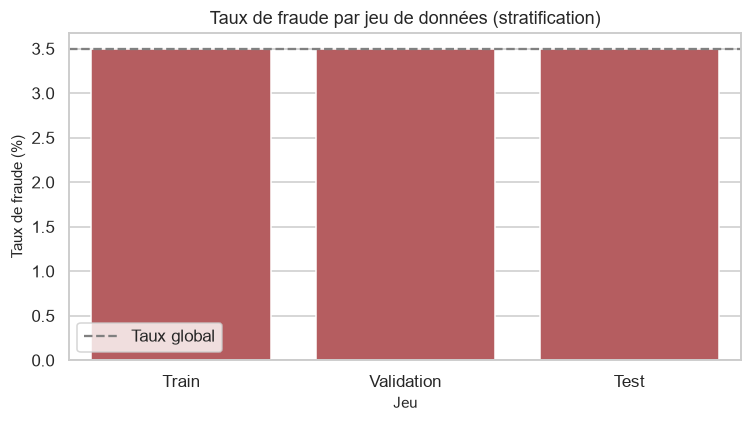

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=resume, x="Jeu", y="Taux de fraude (%)", color="#C44E52", ax=ax)
ax.axhline(y.mean() * 100, ls="--", color="grey", label="Taux global")
ax.set_title("Taux de fraude par jeu de données (stratification)")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "figures" / "03_split_taux_fraude.png", dpi=150)
plt.show()

### Interprétation — Séparation

**Résultat.** Les proportions 70 / 15 / 15 sont respectées et le taux de fraude est quasi identique dans les trois jeux.

**Points forts.** La stratification garantit des estimations comparables entre jeux ; le jeu de test reste intact jusqu'à l'évaluation finale.

**Limites.** La séparation est **aléatoire**, pas chronologique. En production, un modèle prédit le futur à partir du passé : une séparation temporelle donnerait des performances généralement plus faibles et plus réalistes. Cette limite sera discutée dans la conclusion du mémoire. Par ailleurs, si un même porteur de carte apparaît dans plusieurs jeux, une légère optimisation est possible.

In [11]:
# Sauvegarde des trois jeux pour les scripts d'entraînement (Chapitre 8)
pd.concat([X_train, y_train], axis=1).to_parquet(PROC / "train.parquet", index=False)
pd.concat([X_val, y_val], axis=1).to_parquet(PROC / "val.parquet", index=False)
pd.concat([X_test, y_test], axis=1).to_parquet(PROC / "test.parquet", index=False)
print("train.parquet, val.parquet et test.parquet sauvegardés dans", PROC)

train.parquet, val.parquet et test.parquet sauvegardés dans D:\TRAVAUX_LEDESTIN\Codes\Code_Python_Jupyter\ML_Project\data\processed


## 7.4 Gestion du déséquilibre des classes

Le déséquilibre (≈ 1 fraude pour 27 transactions légitimes) pousse un classifieur à « ignorer » la classe minoritaire : prédire toujours *légitime* donnerait ≈ 96,5 % d'accuracy avec un Recall nul. Trois stratégies du plan sont comparées :

| Stratégie | Principe | Risque principal |
|---|---|---|
| **Class Weight** | Pondérer l'erreur sur la classe fraude dans la fonction de perte (`class_weight`, `scale_pos_weight`) | Peut dégrader la calibration des probabilités |
| **SMOTE** | Créer des fraudes synthétiques par interpolation entre voisins | Interpolation non réaliste sur variables binaires / codes ; coût mémoire |
| **Random Undersampling** | Retirer au hasard des transactions légitimes | Perte massive d'information (≈ 96 % des légitimes) |

**Protocole.** Chaque stratégie est comparée à une absence de traitement (*baseline*), avec deux modèles de référence (régression logistique et XGBoost), **entraînée sur le Train uniquement** et **évaluée sur la Validation**. Les rééchantillonnages sont placés dans un `Pipeline` pour ne jamais toucher aux données de validation. Métriques : **PR-AUC** (adaptée aux classes rares), **ROC-AUC**, **Recall** et **Precision** à 0,5, et **F2 au seuil optimal** (le Recall compte quatre fois plus que la Precision, en cohérence avec le besoin métier).

In [12]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Ratio légitimes / fraudes dans le Train : {ratio:.1f}")

xgb = dict(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method="hist",
           eval_metric="aucpr", n_jobs=-1, random_state=SEED)

pipelines = {
    # ------------------------------ Régression logistique (standardisation obligatoire)
    ("Régression logistique", "Aucun traitement"): ImbPipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=500, random_state=SEED))]),
    ("Régression logistique", "Class Weight"):     ImbPipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=500, class_weight="balanced", random_state=SEED))]),
    ("Régression logistique", "SMOTE"):            ImbPipeline([("sc", StandardScaler()), ("re", SMOTE(random_state=SEED)), ("clf", LogisticRegression(max_iter=500, random_state=SEED))]),
    ("Régression logistique", "Undersampling"):    ImbPipeline([("sc", StandardScaler()), ("re", RandomUnderSampler(random_state=SEED)), ("clf", LogisticRegression(max_iter=500, random_state=SEED))]),
    # ------------------------------ XGBoost (pas de standardisation nécessaire)
    ("XGBoost", "Aucun traitement"): ImbPipeline([("clf", XGBClassifier(**xgb))]),
    ("XGBoost", "Class Weight"):     ImbPipeline([("clf", XGBClassifier(scale_pos_weight=ratio, **xgb))]),
    ("XGBoost", "SMOTE"):            ImbPipeline([("re", SMOTE(random_state=SEED)), ("clf", XGBClassifier(**xgb))]),
    ("XGBoost", "Undersampling"):    ImbPipeline([("re", RandomUnderSampler(random_state=SEED)), ("clf", XGBClassifier(**xgb))]),
}
print(len(pipelines), "combinaisons modèle x stratégie à évaluer")

Ratio légitimes / fraudes dans le Train : 27.6
8 combinaisons modèle x stratégie à évaluer


L'exécution de la cellule suivante peut prendre plusieurs minutes (SMOTE double presque la taille du jeu d'entraînement).

In [13]:
resultats = []
for (modele, strategie), pipe in pipelines.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:, 1]

    # Seuil optimal pour le F2 sur la validation
    prec, rec, seuils = precision_recall_curve(y_val, proba)
    f2 = 5 * prec * rec / (4 * prec + rec + 1e-12)
    pred = (proba >= 0.5).astype(int)

    resultats.append({
        "Modèle": modele, "Stratégie": strategie,
        "ROC-AUC": roc_auc_score(y_val, proba),
        "PR-AUC": average_precision_score(y_val, proba),
        "Recall (seuil 0,5)": recall_score(y_val, pred),
        "Precision (seuil 0,5)": precision_score(y_val, pred, zero_division=0),
        "F2 (seuil optimal)": f2[:-1].max(),
        "Durée (s)": time.time() - t0,
    })
    print(f"{modele:22s} | {strategie:17s} | PR-AUC = {resultats[-1]['PR-AUC']:.3f} | {resultats[-1]['Durée (s)']:.0f} s")

comparaison = pd.DataFrame(resultats)
comparaison.to_csv(ROOT / "outputs" / "imbalance_comparison.csv", index=False)

Régression logistique  | Aucun traitement  | PR-AUC = 0.333 | 12 s
Régression logistique  | Class Weight      | PR-AUC = 0.307 | 21 s
Régression logistique  | SMOTE             | PR-AUC = 0.309 | 36 s
Régression logistique  | Undersampling     | PR-AUC = 0.302 | 2 s
XGBoost                | Aucun traitement  | PR-AUC = 0.653 | 10 s
XGBoost                | Class Weight      | PR-AUC = 0.618 | 10 s
XGBoost                | SMOTE             | PR-AUC = 0.573 | 30 s
XGBoost                | Undersampling     | PR-AUC = 0.582 | 2 s


In [14]:
comparaison.set_index(["Modèle", "Stratégie"])

ROC-AUC  PR-AUC  Recall (seuil 0,5)  \
Modèle                Stratégie                                               
Régression logistique Aucun traitement    0.831   0.333               0.145   
                      Class Weight        0.836   0.307               0.739   
                      SMOTE               0.835   0.309               0.742   
                      Undersampling       0.836   0.302               0.741   
XGBoost               Aucun traitement    0.926   0.653               0.428   
                      Class Weight        0.931   0.618               0.804   
                      SMOTE               0.906   0.573               0.442   
                      Undersampling       0.926   0.582               0.812   

                                        Precision (seuil 0,5)  \
Modèle                Stratégie                                 
Régression logistique Aucun traitement                  0.766   
                      Class Weight                      0.106   
                      SMOTE                             0.105   
                      Undersampling                     0.106   
XGBoost               Aucun traitement                  0.883   
                      Class Weight                      0.237   
                      SMOTE                             0.748   
                      Undersampling                     0.196   

                                        F2 (seuil optimal)  Durée (s)  
Modèle                Stratégie                                        
Régression logistique Aucun traitement               0.391     11.836  
                      Class Weight                   0.387     20.951  
                      SMOTE                          0.391     35.749  
                      Undersampling                  0.390      2.400  
XGBoost               Aucun traitement               0.628     10.231  
                      Class Weight                   0.616      9.627  
                      SMOTE                          0.571     30.248  
                      Undersampling                  0.595      2.250

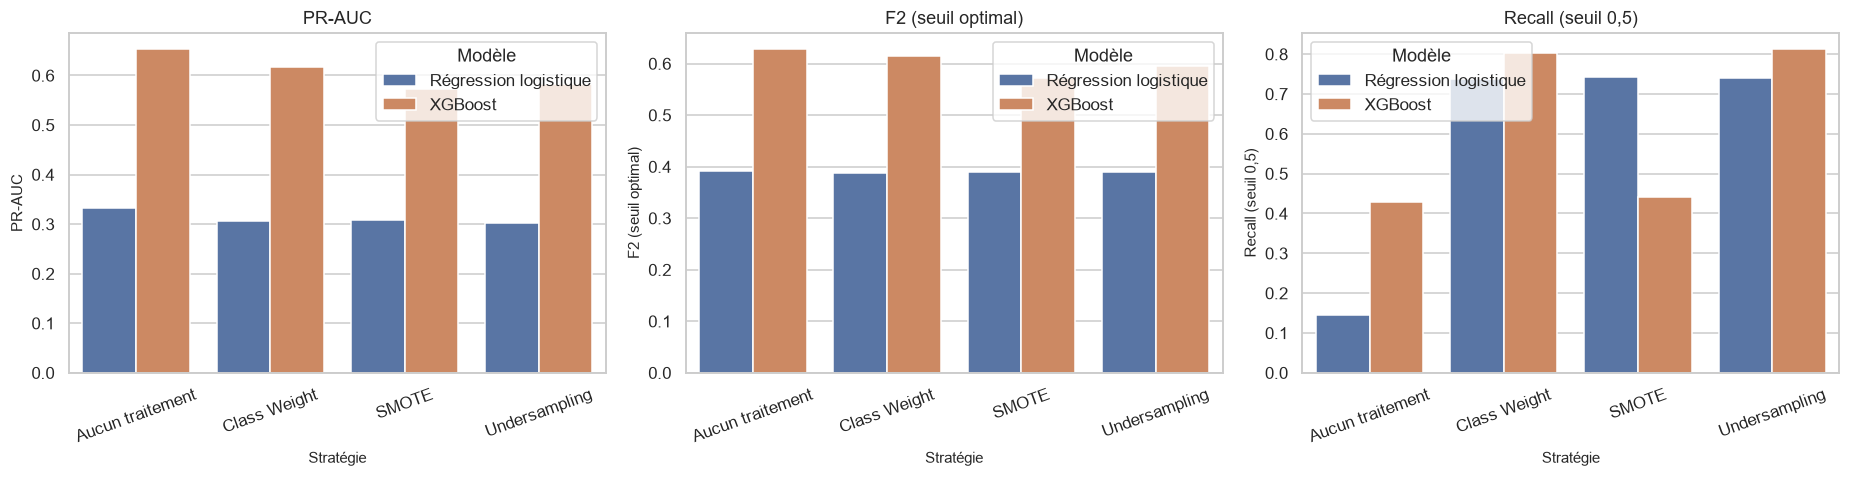

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metrique in zip(axes, ["PR-AUC", "F2 (seuil optimal)", "Recall (seuil 0,5)"]):
    sns.barplot(data=comparaison, x="Stratégie", y=metrique, hue="Modèle", ax=ax)
    ax.set_title(metrique)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "figures" / "03_comparaison_desequilibre.png", dpi=150)
plt.show()

### Interprétation — Comparaison des stratégies

**Résultat (à lire dans le tableau et les graphiques ci-dessus).**
- *Aucun traitement* : Recall à 0,5 faible, car le modèle est peu incité à prédire la classe rare au seuil par défaut. Le classement des observations (ROC-AUC, PR-AUC) peut pourtant rester bon : le problème tient surtout au **seuil**, pas toujours au modèle.
- *Class Weight* : le Recall à 0,5 augmente nettement et la PR-AUC reste proche de la baseline, car aucune donnée n'est modifiée.
- *SMOTE* : coût de calcul plus élevé pour un gain rarement supérieur ; la qualité dépend de la pertinence des voisins dans un espace de plus de 200 dimensions.
- *Undersampling* : Recall élevé mais **Precision très basse** et PR-AUC en baisse, car l'information de ≈ 96 % des transactions légitimes est écartée.

**Points forts / limites des stratégies.**
- *Class Weight* : simple, sans perte d'information, sans coût mémoire, natif dans les trois modèles imposés. Limite : probabilités non calibrées (acceptable, car on exploite un classement et un seuil).
- *SMOTE* : enrichit la classe rare. Limite : crée des points synthétiques irréalistes sur les variables binaires (One Hot) et les codes catégoriels (`card1`, `P_emaildomain`) qui ne se prêtent pas à l'interpolation.
- *Undersampling* : rapide. Limite : forte perte d'information et instabilité.

La comparaison est faite sur deux modèles de référence et un jeu de validation unique : elle indique une tendance, non une preuve définitive.

In [16]:
classement = (comparaison.groupby("Stratégie")[["PR-AUC", "F2 (seuil optimal)", "Recall (seuil 0,5)", "Precision (seuil 0,5)"]]
              .mean().sort_values("F2 (seuil optimal)", ascending=False))
display(classement)
print("Meilleure stratégie selon le F2 moyen sur la validation :", classement.index[0])
print("Meilleure stratégie selon la PR-AUC moyenne            :", classement["PR-AUC"].idxmax())

,PR-AUC,F2 (seuil optimal),"Recall (seuil 0,5)","Precision (seuil 0,5)"
Stratégie,,,,
Aucun traitement,0.493,0.509,0.286,0.824
Class Weight,0.463,0.502,0.771,0.172
Undersampling,0.442,0.493,0.777,0.151
SMOTE,0.441,0.481,0.592,0.426


Meilleure stratégie selon le F2 moyen sur la validation : Aucun traitement
Meilleure stratégie selon la PR-AUC moyenne            : Aucun traitement


## 7.5 Stratégie retenue : **Class Weight**

**Décision.** Les trois scripts d'entraînement du chapitre 8 utilisent la pondération des classes : `class_weight="balanced"` (régression logistique), `class_weight="balanced_subsample"` (Random Forest) et `scale_pos_weight = n_légitimes / n_fraudes` (XGBoost).

**Justification.**
1. **Aucune information perdue ni inventée** : contrairement à l'undersampling (≈ 96 % des légitimes écartées) et à SMOTE (fraudes synthétiques interpolées sur des variables binaires et des codes).
2. **Cohérence avec l'objectif métier** : pénaliser davantage les faux négatifs revient à privilégier le Recall, ce qui est exactement le besoin de la détection de fraude.
3. **Jeu de validation et de test à distribution réelle** : les métriques restent interprétables.
4. **Coût de calcul minimal** : pas de doublement du jeu d'entraînement ; décisif pour 413 000 lignes × plus de 200 variables.
5. **Uniformité** : la même stratégie est appliquée aux trois modèles, ce qui rend la comparaison du chapitre 9 équitable.

**Complément.** Le **seuil de décision** sera ajusté sur la validation (maximisation du F2) : c'est le second levier, indépendant du rééchantillonnage, pour favoriser le Recall.

**Réserve (à examiner après exécution).** Lorsque le seuil est optimisé sur la validation, les écarts de PR-AUC et de F2 entre *Aucun traitement* et *Class Weight* sont souvent faibles : le classement des observations change peu, c'est surtout le seuil qui corrige le déséquilibre. Dans ce cas, `Class Weight` est maintenu car il produit des modèles dont le Recall à 0,5 est déjà raisonnable, sans coût de calcul, et il reste cohérent avec le plan. Si, en revanche, une autre stratégie domine nettement à la fois la PR-AUC et le F2 pour les deux modèles de référence, il faut le signaler dans le mémoire et soit justifier le maintien de `Class Weight`, soit adapter l'entraînement dans les scripts.

## 7.6 Synthèse du chapitre 7

- **Variables** : identifiants, `TransactionDT` et variables redondantes retirés ; sélection non supervisée sans fuite.
- **Séparation** : 70 / 15 / 15 %, stratifiée ; fichiers `train/val/test.parquet` prêts pour les scripts.
- **Déséquilibre** : Class Weight retenu (SMOTE et Undersampling comparés).
- **Étape suivante** : exécuter `scripts/train_logistic.py`, `train_random_forest.py` et `train_xgboost.py`, puis le notebook 04.